# Full-Body Shaping — Final Pose (Left vs. Right)

Two virtual elements act on the arm at once: a Gaussian pushing on segment 1
(`gauss_seg1`, s=1/3) and a linear spring pulling the tip (`lin_seg3`, s=1.0).
Two configs, identical except the tip goal's X sign:
`GUI_MultiVMC_Config_linear_right.py` (+X) and `GUI_MultiVMC_Config_linear_left.py`
(-X). Both goals and strengths are tuned live from the GUI.

There is no condition sweep here — just one recording per side, and only the
settled pose at the end of each matters. This notebook loads both recordings
and draws the arm's actual shape as the motor encoders saw it (FK from
`q_motor`, not the virtual model's internal reference), averaged over the
last few seconds of each run, overlaid for comparison.

In [7]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../Kinematics'))
import glob
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from FK_Multi import FK_Multi
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size

GRID = False
FONT_SIZE = 18
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

S_BACKBONE = np.linspace(0.0, 1.0, 25)  # s-samples along the arm for FK


def save_fig(fig, folder, name):
    """Every figure as PDF and SVG, next to the run it came from."""
    for ext in ('pdf', 'svg'):
        fig.savefig(os.path.join('outputs', folder, f'{name}.{ext}'))

## Load the runs

Record each side with (from `ContactAndShaping/`, arm already homed and
`start_arm.sh` running) — `COLLECTED_DATA = False` in both configs already,
so this saves on the first try:

```bash
# Right:
python3 ../VMC/GUI_MultiVMC_Torque.py --config _linear_right --run right
python3 ../VMC/GUI_MultiVMC.py --config _linear_right

# Left:
python3 ../VMC/GUI_MultiVMC_Torque.py --config _linear_left --run left
python3 ../VMC/GUI_MultiVMC.py --config _linear_left
```

Shape the pose with the GUI sliders, then Ctrl+C the torque node once you're
happy — that writes `outputs/body_shaping/right.npz` (or `left.npz`).
Re-running with the same `--run` name overwrites it. `RUNS` below only needs
to change if you deliberately pick different `--run` names; either side
missing is skipped with a message, not an error, so you can run this after
recording just one of the two.

In [8]:
FOLDER = 'body_shaping'
RUNS = {
    'Right': 'right',   # --run name used with GUI_MultiVMC_Config_linear_right.py
    'Left':  'left',    # --run name used with GUI_MultiVMC_Config_linear_left.py
}
SETTLE_TAIL_S = 3.0   # [s] average the last this-many seconds as "the final pose"

runs = {}
for label, run_name in RUNS.items():
    path = os.path.join('outputs', FOLDER, f'{run_name}.npz')
    if not os.path.exists(path):
        found = sorted(glob.glob(os.path.join('outputs', FOLDER, '*.npz')))
        print(f"[skip] {label}: {path} not found. "
              f"Available in outputs/{FOLDER}/: {[os.path.basename(f) for f in found] or 'nothing'}")
        continue

    d = np.load(path, allow_pickle=True)
    t    = d['t']
    tail = t >= t[-1] - SETTLE_TAIL_S   # "final pose" = mean over the last SETTLE_TAIL_S seconds

    q_final    = d['q_motor'][tail].mean(axis=0)
    goal_final = d['goal'][tail].mean(axis=0)          # (N_VC, 3)
    comp_names = [str(n) for n in d['comp_names']]
    s_params   = d['comp_s_params']
    backbone   = np.array([FK_Multi(q_final, s)[:3] for s in S_BACKBONE])

    runs[label] = dict(path=path, backbone=backbone, comp_names=comp_names,
                       s_params=s_params, goal_final=goal_final)

    print(f'{label}   [{path}]')
    print(f'  Full run:   {len(t)} samples, {t[-1]:.1f} s')
    print(f'  Final pose: mean of last {SETTLE_TAIL_S:.1f} s ({int(tail.sum())} samples)')
    for name, s, g in zip(comp_names, s_params, goal_final):
        print(f'    {name:<12} s={s:.3f}   goal = ({g[0]*100:5.1f}, {g[1]*100:5.1f}, {g[2]*100:5.1f}) cm')
    print()

if not runs:
    raise FileNotFoundError(f"No runs found in outputs/{FOLDER}/ -- record at least one side first.")

Right   [outputs/body_shaping/right.npz]
  Full run:   38851 samples, 116.7 s
  Final pose: mean of last 3.0 s (990 samples)
    lin_seg3     s=1.000   goal = ( 34.3,  -3.9,  43.5) cm
    gauss_seg1   s=0.333   goal = (  4.5,  -0.3,  14.5) cm

Left   [outputs/body_shaping/left.npz]
  Full run:   52467 samples, 151.4 s
  Final pose: mean of last 3.0 s (988 samples)
    lin_seg3     s=1.000   goal = (-16.7,   1.6,  43.5) cm
    gauss_seg1   s=0.333   goal = ( -6.7,   1.9,  14.5) cm



## Backbones at the final pose

Side view (X-Z) only. Backbone color = side (Right/Left, top-left legend);
markers are a neutral color deliberately different from both backbone colors,
so they read clearly against either line — shape = element (star = tip
spring, circle = Gaussian), filled = attachment point on the arm, open = that
element's goal at the same instant (bottom-right legend). The gap between a
filled and open marker of the same shape is how far that spring/Gaussian is
still pulling.

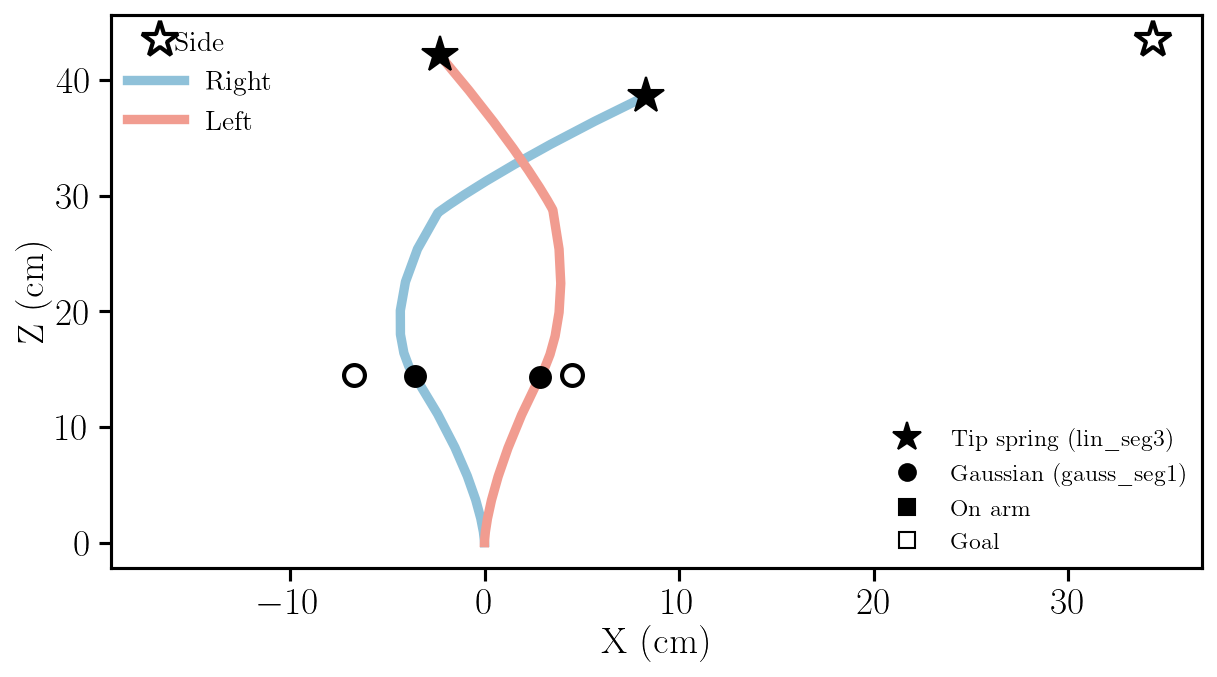

Saved → outputs/body_shaping/right_left_backbone.{pdf,svg}


In [9]:
# ---- figure size ----
FIG_W        = 8.0     # in -- TUNE THIS: total figure width
PANEL_ASPECT = 0.55    # TUNE THIS: panel height as a fraction of FIG_W
LINEWIDTH    = 4.5     # TUNE THIS: backbone line thickness
MARKER_COLOR = 'black'  # TUNE THIS: spring/goal marker color -- deliberately not a backbone color, so markers read clearly against either side's line

fig, ax = plt.subplots(figsize=(FIG_W, FIG_W * PANEL_ASPECT), layout='constrained')

for i, (label, r) in enumerate(runs.items()):
    color    = COLORS[i]
    backbone = r['backbone']
    ax.plot(backbone[:, 0] * 100, backbone[:, 2] * 100, color=color, linewidth=LINEWIDTH, zorder=3, label=label)

    for name, s, g in zip(r['comp_names'], r['s_params'], r['goal_final']):
        p      = backbone[np.argmin(np.abs(S_BACKBONE - s))]
        marker = '*' if name == 'lin_seg3' else 'o'
        size   = 18 if name == 'lin_seg3' else 10

        ax.plot(p[0] * 100, p[2] * 100, marker, color=MARKER_COLOR, markersize=size, zorder=4)
        ax.plot(g[0] * 100, g[2] * 100, marker, color=MARKER_COLOR, markersize=size, zorder=4,
               markerfacecolor='none', markeredgewidth=2.0)

ax.set_xlabel('X (cm)')
ax.set_ylabel('Z (cm)')
ax.grid(GRID)

# Two legends on the same axes -- add_artist keeps the first one when the
# second .legend() call would otherwise replace it.
side_legend = ax.legend(fontsize=LEGEND_FONT_SIZE, loc='upper left', framealpha=0.9, title='Side')
ax.add_artist(side_legend)

shape_handles = [
    Line2D([0], [0], marker='*', color=MARKER_COLOR, markersize=14, linestyle='None', label='Tip spring (lin_seg3)'),
    Line2D([0], [0], marker='o', color=MARKER_COLOR, markersize=8, linestyle='None', label='Gaussian (gauss_seg1)'),
    Line2D([0], [0], marker='s', color=MARKER_COLOR, markersize=8, linestyle='None', markerfacecolor=MARKER_COLOR, label='On arm'),
    Line2D([0], [0], marker='s', color=MARKER_COLOR, markersize=8, linestyle='None', markerfacecolor='none', label='Goal'),
]
ax.legend(handles=shape_handles, fontsize=LEGEND_FONT_SIZE * 0.85, loc='lower right', framealpha=0.9)

name = '_'.join(RUNS[label] for label in runs)
save_fig(fig, FOLDER, f'{name}_backbone')
plt.show()
print(f"Saved → outputs/{FOLDER}/{name}_backbone.{{pdf,svg}}")